In [40]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain_openai import ChatOpenAI

from dotenv import load_dotenv

if os.environ['AICREDITS_API_KEY']:
    print("AICredits API Key is set.")
else:
    raise ValueError("AICredits API Key is not set.")

AICredits API Key is set.


In [41]:
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from  langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser, PydanticOutputParser

In [42]:
llm_openai = ChatOpenAI(
    model="gpt-5-mini",
    base_url="https://api.aicredits.in/v1",
    api_key=os.environ["AICREDITS_API_KEY"],
)

In [43]:
# TOOL - 1 [News Search Tool]

from langchain_community.tools import DuckDuckGoSearchRun

search_tool = DuckDuckGoSearchRun(description="This is a tool to search the web for news")


# TOOL - 2 [Wikipedia Search Tool]

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(),description="This is a tool to search Wikipedia")


# TOOL - 3 [Custom Enterprise Tool]

from langchain.tools import tool

@tool
def enterprise_tool(query:str)-> str:

    """This is a tool to send emails to employees"""
    
    return "Email Sent"

In [44]:
ToolKit = [search_tool, wikipedia_tool, enterprise_tool]
ToolKit

[DuckDuckGoSearchRun(description='This is a tool to search the web for news', api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description='This is a tool to search Wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\AgenticAI\\Langchain_Tutorial\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='This is a tool to send emails to employees', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x00000150D56EF420>)]

## **ReAct Agent**

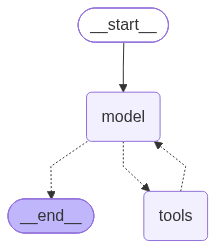

In [45]:
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="gpt-5-mini",
    temperature=0.1,
    base_url="https://api.aicredits.in/v1",
    api_key=os.environ["AICREDITS_API_KEY"],    
)
agent = create_agent(model, tools=ToolKit)
agent

## **ReAct Agent Invoke with Streams**

In [48]:
from langchain_community.utilities import DuckDuckGoSearchAPIWrapper
from langchain_community.tools import DuckDuckGoSearchRun

# Reconfigure the internal engine parameters to parse a max text envelope
wrapper = DuckDuckGoSearchAPIWrapper(max_results=5) 
search_tool = DuckDuckGoSearchRun(api_wrapper=wrapper)

# Pass this directly into your toolkit
ToolKit = [search_tool]


In [49]:
example_query = "Give me the latest news about the stock market"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Give me the latest news about the stock market
================================== Ai Message ==================================
Tool Calls:
  duckduckgo_search (call_aLG9G8qLrHBwoWEhCEy6Fv9z)
 Call ID: call_aLG9G8qLrHBwoWEhCEy6Fv9z
  Args:
    query: stock market news today Dow S&P 500 Nasdaq latest
================================= Tool Message =================================
Name: duckduckgo_search

Track the stock market today with ChartingLens. This page provides a real-time overview of major market indices including the S&P 500, Dow Jones Industrial Average, Nasdaq Composite, and Russell 2000. 1 hour ago · What does the US stock market today snapshot include? It includes the latest cached S&P 500, Nasdaq Composite, Dow Jones, Russell 2000 and VIX levels, plus leading gainers and losers. 13 hours ago · US stock market closing data for Oct 11, 2026. S&P 500, Dow Jones, Nasdaq performance, top gainers

In [39]:
llm_openai.invoke("What's the latest news about the stock market?")

AIMessage(content='I don’t have live internet access, so I can’t pull today’s headlines or real‑time prices. I can, however, tell you how to get an accurate snapshot in seconds and what to look for — or I can analyze specific tickers, headlines, or themes if you paste them here.\n\nQuick ways to get today’s market news and data\n- Market dashboards: Google Finance, Yahoo Finance, TradingView — show indices, top movers, futures, and news.\n- News outlets: Bloomberg, Reuters, CNBC, WSJ, Financial Times — for headlines and context.\n- Brokerages/apps: Schwab, Fidelity, Robinhood, E*TRADE, Webull — real‑time quotes + alerts.\n- TV/radio: CNBC, Bloomberg TV, NPR Marketplace for live coverage and expert commentary.\n- Economic calendar: Investing.com or ForexFactory for scheduled data releases (CPI, payrolls, Fed decisions).\n- Social/real‑time feeds: Twitter/X (follow verified financial reporters), StockTwits (ticker chatter) — use cautiously.\n\nFast checklist for a market snapshot\n- Majo

In [47]:
llm_binded = llm_openai.bind_tools(ToolKit)
llm_binded.invoke("What is the latest news about the stock market")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 221, 'prompt_tokens': 200, 'total_tokens': 421, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 192, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'cost': 0.056596569408719995, 'cost_details': {'completion_cost_inr': 0.05084488552572, 'prompt_cost_inr': 0.005751683883000001}, 'latency_ms': 1817}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-EXndu7sLlKYkcKmzQLQBSyd9d7wDb', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a12b18-09de-7252-925b-e1a695337999-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'stock market news today'}, 'id': 'call_sig07ntet0f9zX